In [1]:
## Only valid for Colab otherwise install using conda or pip in the Virtual environment
!pip install "ray[tune]"
!pip -q install scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 9.7 MB/s eta 0:00:00


100%|██████████| 345M/345M [00:24<00:00, 14.0MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.56MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 9.90MB/s]


Number of images: 1020
Tensor shape: torch.Size([3, 500, 667])
 image dimensionstorch.Size([3, 500, 667])
Tensor shape: torch.Size([3, 514, 500])
 image dimensionstorch.Size([3, 514, 500])
Tensor shape: torch.Size([3, 500, 664])
 image dimensionstorch.Size([3, 500, 664])
Tensor shape: torch.Size([3, 500, 667])
 image dimensionstorch.Size([3, 500, 667])
Tensor shape: torch.Size([3, 500, 654])
 image dimensionstorch.Size([3, 500, 654])
Tensor shape: torch.Size([3, 500, 508])
 image dimensionstorch.Size([3, 500, 508])
Tensor shape: torch.Size([3, 667, 500])
 image dimensionstorch.Size([3, 667, 500])
Tensor shape: torch.Size([3, 500, 575])
 image dimensionstorch.Size([3, 500, 575])


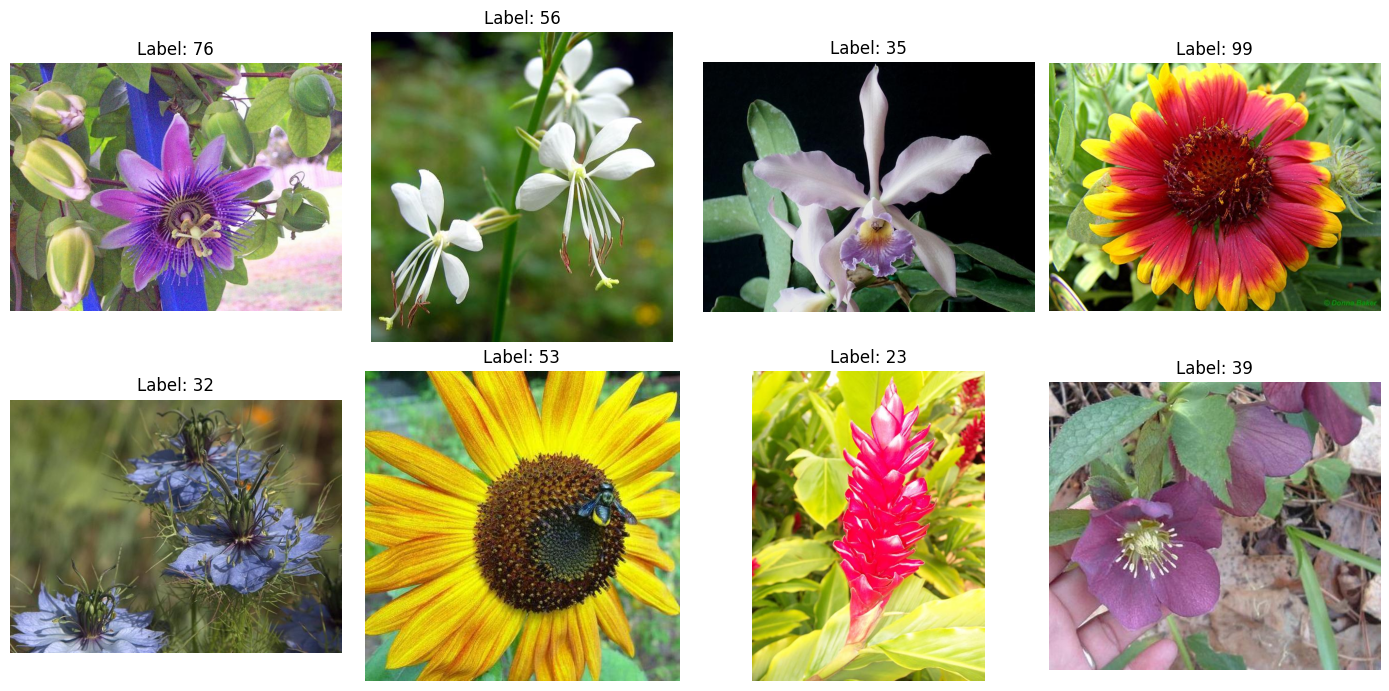

In [2]:
## Read the data and display a few images and labels for sanity
import torch
import torchvision
from torchvision.datasets import Flowers102
import matplotlib.pyplot as plt
import random
from torchvision import transforms

to_tensor = transforms.ToTensor()

# Download the Oxford Flowers-102 dataset
dataset = Flowers102(
    root="/content/data",
    split="train",
    download=True
)

print("Number of images:", len(dataset))

# Display a few random images and their labels
num_images = 8
indices = random.sample(range(len(dataset)), num_images)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.ravel()

for ax, idx in zip(axes, indices):
    image, label = dataset[idx]
    image_tensor = to_tensor(image)

    print(f"Tensor shape: {image_tensor.shape}")
    ax.imshow(image)
    print(f" image dimensions{image_tensor.shape}")
    ax.set_title(f"Label: {label}")  # Labels are flower category IDs
    ax.axis("off")

plt.tight_layout()
plt.show()

In [3]:
import os
import tempfile
from functools import partial
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader

from ray import tune
from ray.tune import Checkpoint
from ray.tune.schedulers import ASHAScheduler
from sklearn.metrics import accuracy_score, f1_score

""" Example is based on https://docs.pytorch.org/tutorials/beginner/hyperparameter_tuning_tutorial.html"""

# I have used ImageNet statistics for this task
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
NUM_CLASSES = 102
IMAGE_SIZE = 224 # All inputs should be resizesd to 224x224
def load_data(data_dir):
    """
    Download Flowers102 and return train, validation, and test datasets.
    """
    ## Data augmentation techniques can be added here..
    train_tf = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

    eval_tf = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])

    trainset = torchvision.datasets.Flowers102(
        root=data_dir,
        split="train",
        transform=train_tf,
        download=True,
    )

    valset = torchvision.datasets.Flowers102(
        root=data_dir,
        split="val",
        # validation images can have the same trasform as test set
        transform=eval_tf,
        download=True,
    )

    testset = torchvision.datasets.Flowers102(
        root=data_dir,
        split="test",
        transform=eval_tf,
        download=True,
    )

    return trainset, valset, testset


def build_resnet18(num_classes=NUM_CLASSES):
    #Change the ResNet-18 to classify 102 output classes.

    model = torchvision.models.resnet18(
        weights=None,
        num_classes=num_classes,
    )

    return model


def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            predictions = outputs.argmax(dim=1)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    average_loss = total_loss / total
    accuracy = correct / total

    # weighted F1 accounts for class frequencies
    f1_weighted = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0)
    return average_loss, accuracy, f1_weighted

def train_model(config, data_dir=None, max_epochs=10):
    #Trainable function executed by each Ray Tune trial.

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = build_resnet18().to(device)
    criterion = nn.CrossEntropyLoss()
    ## please note if we use SGD then the config will change
    optimizer = optim.Adam(
        model.parameters(),
        lr=config["lr"]
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=max_epochs,
    )


    start_epoch = 0
    checkpoint = tune.get_checkpoint()

    if checkpoint is not None:
        with checkpoint.as_directory() as checkpoint_dir:
            checkpoint_path = Path(checkpoint_dir) / "checkpoint.pt"

            state = torch.load(
                checkpoint_path,
                map_location=device,
            )

            start_epoch = state["epoch"]
            model.load_state_dict(state["model"])
            optimizer.load_state_dict(state["optimizer"])
            scheduler.load_state_dict(state["scheduler"])

    trainset, valset, _ = load_data(data_dir)

    train_loader = DataLoader(
        trainset,
        batch_size=int(config["batch_size"]),
        shuffle=True,
        num_workers=2
    )

    val_loader = DataLoader(
        valset,
        batch_size=128,
        shuffle=False,
        num_workers=2,
    )

    for epoch in range(start_epoch, max_epochs):
        model.train()

        running_loss = 0.0
        total_train = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            total_train += labels.size(0)

        scheduler.step()

        train_loss = running_loss / total_train
        val_loss, val_accuracy, val_f1_score = evaluate_model(model, val_loader, criterion, device)

        print(
            f"Epoch {epoch + 1}/{max_epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Validation loss: {val_loss:.4f} | "
            f"Validation accuracy: {val_accuracy:.4f}"
        )

        # Save a checkpoint for Ray Tune (temp dir is unique per report)
        # per-report temp directory to save the checpoints
        with tempfile.TemporaryDirectory() as tmp_dir:
            torch.save(
                {
                    "epoch": epoch + 1,
                    "model": model.state_dict(),
                    "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(),
                },
                Path(tmp_dir) / "checkpoint.pt",
            )

            tune.report(
                {
                    "loss": val_loss,
                    "accuracy": val_accuracy,
                    "f1_score": val_f1_score,
                },
                checkpoint=Checkpoint.from_directory(tmp_dir),
            )

def test_best_model(best_result, data_dir):
    # Load and evaluate the best Ray Tune trial on the Flowers102 test set.
    device = "cuda" if torch.cuda.is_available() else "cpu"

    model = build_resnet18().to(device)



    with best_result.checkpoint.as_directory() as checkpoint_dir:
        checkpoint_path = Path(checkpoint_dir) / "checkpoint.pt"

        state = torch.load(
            checkpoint_path,
            map_location=device,
        )

        model.load_state_dict(state["model"])

    _, _, testset = load_data(data_dir)

    test_loader = DataLoader(
        testset,
        batch_size=128,
        shuffle=False,
        num_workers=2,
        pin_memory=(device == "cuda"),
    )

    criterion = nn.CrossEntropyLoss()
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    test_loss = total_loss / len(test_loader.dataset)

    # Overall classification accuracy
    test_accuracy = accuracy_score(all_labels, all_predictions)

    # weighted F1 accounts for class frequencies
    test_f1_weighted = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0)

    print(f"Best trial test loss: {test_loss:.4f}")
    print(f"Best trial test accuracy: {test_accuracy:.4f}")
    print(f"Best trial test F1 score (weighted): {test_f1_weighted:.4f}")

    return {
        "test_loss": test_loss,
        "test_accuracy": test_accuracy}

## run trainable multiple times using configurations sampled from search_space
## num_samples trials, use loss as a metric (lower loss better)
## scheduler is used to manage trials efficiently
def main_method(num_samples=10, max_epochs=10, gpus_per_trial=1):

    data_dir = os.path.abspath("./flowers_data")
    # Download the dataset once before starting Ray trials.
    load_data(data_dir)

    # search space can be big e.g., use of different LRs and batch sizes
    ## search spaces for optimizers e.g., SGD, AdamW would be differnet
    search_space = {
        "lr": tune.loguniform(1e-4, 1e-1),
        "batch_size": tune.choice([16, 32, 64]),
    }

    # grace_period is useful when models need several epochs to start learning
    # reduction factor for number of trials to continue
    scheduler = ASHAScheduler(
        time_attr="training_iteration",
        max_t=max_epochs,
        grace_period=5,
        reduction_factor=2,
    )

    trainable = tune.with_resources(
        partial(
            train_model,
            data_dir=data_dir,
            max_epochs=max_epochs,
        ),
        resources={
            "cpu": 2,
            "gpu": gpus_per_trial,
        },
    )

    tuner = tune.Tuner(
        trainable,
        tune_config=tune.TuneConfig(
            metric="loss",
            mode="min",
            scheduler=scheduler,
            num_samples=num_samples,
        ),
        param_space=search_space,
    )

    results = tuner.fit()

    best_result = results.get_best_result(
        metric="loss",
        mode="min",
        scope="last",
    )

    print("\nBest trial configuration:")
    print(best_result.config)

    print(f"\nBest validation loss: {best_result.metrics['loss']:.4f}")
    print(f"Best validation accuracy: {best_result.metrics['accuracy']:.4f}")

    test_best_model(best_result, data_dir)


main_method(num_samples=10, max_epochs=20,
        gpus_per_trial=1)

100%|██████████| 345M/345M [00:23<00:00, 14.4MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.92MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 49.3MB/s]
2026-10-11 17:53:26,312	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-10-11 17:53:26,314	INFO authentication_token_setup.py:50 -- Generated new authentication token and saved to /root/.ray/auth_token
2026-10-11 17:53:38,351	INFO worker.py:2033 -- Started a local Ray instance.
2026-10-11 17:53:42,329	INFO tune.py:253 -- Initializing Ray automatically. For cluster usage or custom Ray initialization, call `ray.init(...)` before `Tuner(...)`.


+--------------------------------------------------------------------+
| Configuration for experiment     train_model_2026-10-11_17-53-26   |
+--------------------------------------------------------------------+
| Search algorithm                 BasicVariantGenerator             |
| Scheduler                        AsyncHyperBandScheduler           |
| Number of trials                 10                                |
+--------------------------------------------------------------------+

View detailed results here: /root/ray_results/train_model_2026-10-11_17-53-26
To visualize your results with TensorBoard, run: `tensorboard --logdir /tmp/ray/session_2026-10-11_17-53-26_315466_1276/artifacts/2026-10-11_17-53-42/train_model_2026-10-11_17-53-26/driver_artifacts`

Trial status: 10 PENDING
Current time: 2026-10-11 17:53:43. Total running time: 0s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
+--------------------------------------------------------------

(func pid=2254) Checkpoint successfully created at: Checkpoint(filesystem=local, path=/root/ray_results/train_model_2026-10-11_17-53-26/train_model_b262d_00000_0_batch_size=32,lr=0.0018_2026-10-11_17-53-42/checkpoint_000000)
2026-10-11 17:54:08,280	WARNING util.py:212 -- The `callbacks.on_trial_result` operation took 0.746 s, which may be a performance bottleneck.
2026-10-11 17:54:08,283	WARNING util.py:212 -- The `process_trial_result` operation took 0.749 s, which may be a performance bottleneck.
2026-10-11 17:54:08,286	WARNING util.py:212 -- Processing trial results took 0.753 s, which may be a performance bottleneck. Please consider reporting results less frequently to Ray Tune.
2026-10-11 17:54:08,287	WARNING util.py:212 -- The `process_trial_result` operation took 0.753 s, which may be a performance bottleneck.



Trial status: 1 RUNNING | 9 PENDING
Current time: 2026-10-11 17:54:13. Total running time: 30s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
Current best trial: b262d_00000 with loss=28.66510020985323 and params={'lr': 0.0017942034111632836, 'batch_size': 32}
+---------------------------------------------------------------------------------------------------------------------------------+
| Trial name                status              lr     batch_size     iter     total time (s)      loss     accuracy     f1_score |
+---------------------------------------------------------------------------------------------------------------------------------+
| train_model_b262d_00000   RUNNING    0.0017942               32        1            14.7372   28.6651    0.0127451   0.00171206 |
| train_model_b262d_00001   PENDING    0.000127388             64                                                                 |
| train_model_b262d_00002   PENDING    0.0020025

(func pid=2254) Checkpoint successfully created at: Checkpoint(filesystem=local, path=/root/ray_results/train_model_2026-10-11_17-53-26/train_model_b262d_00000_0_batch_size=32,lr=0.0018_2026-10-11_17-53-42/checkpoint_000001)
2026-10-11 17:54:21,009	WARNING util.py:212 -- The `callbacks.on_trial_result` operation took 0.795 s, which may be a performance bottleneck.
2026-10-11 17:54:21,012	WARNING util.py:212 -- The `process_trial_result` operation took 0.798 s, which may be a performance bottleneck.
2026-10-11 17:54:21,013	WARNING util.py:212 -- Processing trial results took 0.800 s, which may be a performance bottleneck. Please consider reporting results less frequently to Ray Tune.
2026-10-11 17:54:21,015	WARNING util.py:212 -- The `process_trial_result` operation took 0.801 s, which may be a performance bottleneck.


...

Trial status: 9 TERMINATED | 1 RUNNING
Current time: 2026-10-11 18:17:16. Total running time: 23min 33s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
Current best trial: b262d_00004 with loss=2.247179579267315 and params={'lr': 0.0002346401478311775, 'batch_size': 16}
+-----------------------------------------------------------------------------------------------------------------------------------+
| Trial name                status                lr     batch_size     iter     total time (s)      loss     accuracy     f1_score |
+-----------------------------------------------------------------------------------------------------------------------------------+
| train_model_b262d_00009   RUNNING      0.0534715               32        8           107.021    4.06377    0.0588235   0.0265074  |
| train_model_b262d_00000   TERMINATED   0.0017942               32       20           248.665    2.82191    0.311765    0.278107   |
| train_model_b262d_00001   TE

(func pid=9736) Checkpoint successfully created at: Checkpoint(filesystem=local, path=/root/ray_results/train_model_2026-10-11_17-53-26/train_model_b262d_00009_9_batch_size=32,lr=0.0535_2026-10-11_17-53-43/checkpoint_000008)
2026-10-11 18:17:23,772	WARNING util.py:212 -- The `callbacks.on_trial_result` operation took 0.737 s, which may be a performance bottleneck.
2026-10-11 18:17:23,775	WARNING util.py:212 -- The `process_trial_result` operation took 0.740 s, which may be a performance bottleneck.
2026-10-11 18:17:23,776	WARNING util.py:212 -- Processing trial results took 0.741 s, which may be a performance bottleneck. Please consider reporting results less frequently to Ray Tune.
2026-10-11 18:17:23,777	WARNING util.py:212 -- The `process_trial_result` operation took 0.741 s, which may be a performance bottleneck.


(func pid=9736) Epoch 10/20 | Train loss: 3.9823 | Validation loss: 4.0171 | Validation accuracy: 0.0588


(func pid=9736) Checkpoint successfully created at: Checkpoint(filesystem=local, path=/root/ray_results/train_model_2026-10-11_17-53-26/train_model_b262d_00009_9_batch_size=32,lr=0.0535_2026-10-11_17-53-43/checkpoint_000009)
2026-10-11 18:17:37,343	WARNING util.py:212 -- The `callbacks.on_trial_result` operation took 0.738 s, which may be a performance bottleneck.
2026-10-11 18:17:37,345	WARNING util.py:212 -- The `process_trial_result` operation took 0.741 s, which may be a performance bottleneck.
2026-10-11 18:17:37,346	WARNING util.py:212 -- Processing trial results took 0.742 s, which may be a performance bottleneck. Please consider reporting results less frequently to Ray Tune.
2026-10-11 18:17:37,347	WARNING util.py:212 -- The `process_trial_result` operation took 0.743 s, which may be a performance bottleneck.
2026-10-11 18:17:37,385	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to '/root/ray_results/train_model_2026-10-11_17-53-26' in 0.


Trial train_model_b262d_00009 completed after 10 iterations at 2026-10-11 18:17:37. Total running time: 23min 54s
+------------------------------------------------------------+
| Trial train_model_b262d_00009 result                       |
+------------------------------------------------------------+
| checkpoint_dir_name                      checkpoint_000009 |
| time_this_iter_s                                    12.821 |
| time_total_s                                     132.70186 |
| training_iteration                                      10 |
| accuracy                                           0.05882 |
| f1_score                                           0.02321 |
| loss                                               4.01709 |
+------------------------------------------------------------+

Trial status: 10 TERMINATED
Current time: 2026-10-11 18:17:37. Total running time: 23min 54s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
Current best trial: b